In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Data
X = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([40, 45, 50, 55, 60], dtype=float)


# Parameters
w = 0.0
b = 0.0

learning_rate = 0.01
epochs = 1000


loss_history = []

for epoch in range(epochs):

    # 1. Prediction
    y_pred = w * X + b

    # 2. Loss
    loss = np.mean((y_pred - y) ** 2)
    loss_history.append(loss)

    # 3. Gradients
    dw = np.mean(2 * X * (y_pred - y))
    db = np.mean(2 * (y_pred - y))

    # 4. Update
    w = w - learning_rate * dw
    b = b - learning_rate * db


print("w:", w)
print("b:", b)
print("Final loss:", loss_history[-1])

w: 5.292458985140623
b: 33.94413026690887
Final loss: 0.20430333595991407


In [23]:
def train_scratch(X, y, learning_rate, epochs):

    w = 0.0
    b = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Prediction
        y_pred = w * X + b

        # Loss
        loss = np.mean((y_pred - y) ** 2)
        loss_history.append(loss)

        # Gradients
        dw = np.mean(2 * X * (y_pred - y))
        db = np.mean(2 * (y_pred - y))

        # Update
        w -= learning_rate * dw
        b -= learning_rate * db

    return w, b, loss_history


In [24]:
learning_rates = [0.001, 0.01, 0.1, 1.0]

In [25]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X.reshape(-1, 1), y)

print("sklearn w:", model.coef_[0])
print("sklearn b:", model.intercept_)

sklearn w: 4.999999999999999
sklearn b: 35.0


In [26]:
def compare_learning_rates(X, y, learning_rates, epochs):

    plt.figure(figsize=(10, 6))

    results = {}

    for lr in learning_rates:

        w, b, loss_history = train_scratch(
            X, y,
            learning_rate=lr,
            epochs=epochs
        )

        results[lr] = {
            "w": w,
            "b": b,
            "final_loss": loss_history[-1]
        }

        plt.plot(
            range(epochs),
            loss_history,
            label=f"LR = {lr}"
        )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Gradient Descent: Different Learning Rates")
    plt.legend()
    plt.yscale("log")
    plt.grid()

    plt.show()

    return results

C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:14: RuntimeWarning: overflow encountered in square
  loss = np.mean((y_pred - y) ** 2)
C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:18: RuntimeWarning: overflow encountered in multiply
  dw = np.mean(2 * X * (y_pred - y))
C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:19: RuntimeWarning: overflow encountered in multiply
  db = np.mean(2 * (y_pred - y))
C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:22: RuntimeWarning: invalid value encountered in scalar subtract
  w -= learning_rate * dw
C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:23: RuntimeWarning: invalid value encountered in scalar subtract
  b -= learning_rate * db


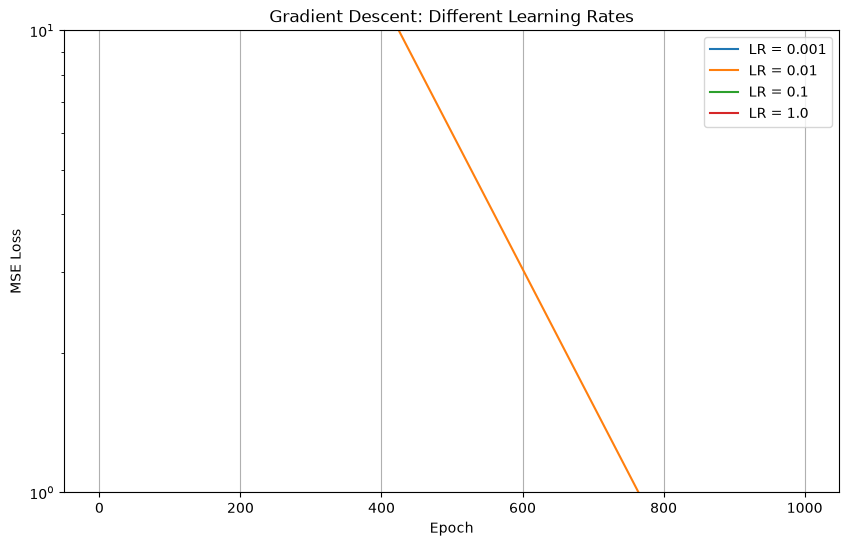


Scratch Results:
LR=0.001: w=11.1663, b=12.7375, loss=90.2720
LR=0.01: w=5.2925, b=33.9441, loss=0.2043
LR=0.1: w=-44286645217146405211253642544752780881557117583785732928703411161950019703128891245918864989969733265064187815303017572842569630104944640.0000, b=-12266690586509788786867851474742837258860644692148622546273659112638609611532183849310225426795780024005981597685546944529461336845844480.0000, loss=13385840216140168262033513765789387875760422163362864392482749895902827068003235009734778392464642273766737768113825464605981952383888066897828342695702372339840179024981071372612374233505190296672193961516960477385902225184092649313431637232360029533474890445291890004721664.0000
LR=1.0: w=nan, b=nan, loss=nan


In [30]:
learning_rates = [0.001, 0.01, 0.1, 1.0]

results = compare_learning_rates(
    X,
    y,
    learning_rates,
    epochs=1000
)

print("\nScratch Results:")

for lr, result in results.items():
    print(
        f"LR={lr}: "
        f"w={result['w']:.4f}, "
        f"b={result['b']:.4f}, "
        f"loss={result['final_loss']:.4f}"
    )



In [28]:
model = LinearRegression()

model.fit(X.reshape(-1, 1), y)

print("\nSklearn Results:")
print(f"w = {model.coef_[0]:.4f}")
print(f"b = {model.intercept_:.4f}")


Sklearn Results:
w = 5.0000
b = 35.0000


In [35]:
for lr in [0.1, 1.0]:
    w, b, loss_history = train_scratch(
        X, y,
        learning_rate=lr,
        epochs=1000
    )

    print(f"LR = {lr}")
    print("First loss:", loss_history[0])
    print("Loss at epoch 10:", loss_history[10])
    print("Loss at epoch 100:", loss_history[100])
    print("Final loss:", loss_history[-1])
    print()

LR = 0.1
First loss: 2550.0
Loss at epoch 10: 1217528.4825356777
Loss at epoch 100: 3.002391970153799e+30
Final loss: 1.3385840216140168e+274

LR = 1.0
First loss: 2550.0
Loss at epoch 10: 3.027963928723907e+30
Loss at epoch 100: 2.7195757201208834e+274
Final loss: nan



C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:14: RuntimeWarning: overflow encountered in square
  loss = np.mean((y_pred - y) ** 2)
C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:18: RuntimeWarning: overflow encountered in multiply
  dw = np.mean(2 * X * (y_pred - y))
C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:19: RuntimeWarning: overflow encountered in multiply
  db = np.mean(2 * (y_pred - y))
C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:22: RuntimeWarning: invalid value encountered in scalar subtract
  w -= learning_rate * dw
C:\Users\sus\AppData\Local\Temp\ipykernel_23456\4109637957.py:23: RuntimeWarning: invalid value encountered in scalar subtract
  b -= learning_rate * db


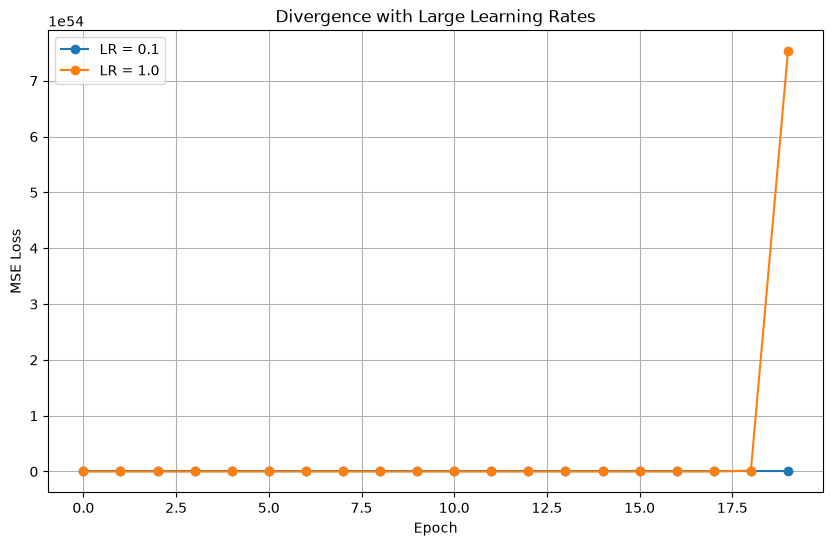

In [36]:
learning_rates = [0.1, 1.0]

plt.figure(figsize=(10, 6))

for lr in learning_rates:

    w, b, loss_history = train_scratch(
        X, y,
        learning_rate=lr,
        epochs=20
    )

    plt.plot(
        range(20),
        loss_history,
        marker="o",
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Divergence with Large Learning Rates")
plt.legend()
plt.grid()

plt.show()